# Exercise 13: Support Vector Machine (Part 2) - Solution
### (010000) Machine Learning - Spring 2026
### Prof. Cheol Jeong, Sejong University

## Task 1 & 2: Load the Wine dataset and split the data.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

wine = load_wine(as_frame=True)

X = wine.data
y = wine.target

feature_names = wine.feature_names
class_names = wine.target_names

print("Feature names:")
print(feature_names)
print()
print("Class names:")
print(class_names)
print()
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Class counts:", np.bincount(y))

Feature names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

Class names:
['class_0' 'class_1' 'class_2']

X shape: (178, 13)
y shape: (178,)
Class counts: [59 71 48]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=520,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test  shape:", X_test.shape)
print("Train class counts:", np.bincount(y_train))
print("Test class counts :", np.bincount(y_test))

X_train shape: (124, 13)
X_test  shape: (54, 13)
Train class counts: [41 50 33]
Test class counts : [18 21 15]


## Task 3: Train three SVM pipelines with different kernels.

In [ ]:
models = {
    "Linear": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="linear", C=10.0))
    ]),
    "Polynomial": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="poly", degree=3, C=10.0, gamma="scale"))
    ]),
    "RBF": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=10.0, gamma="scale"))
    ]),
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    test_acc = model.score(X_test, y_test)

    svm = model.named_steps["svm"]
    n_support_each_class = svm.n_support_
    total_support_vectors = svm.n_support_.sum()

    results[name] = {
        "model": model,
        "test_acc": test_acc,
        "n_support_each_class": n_support_each_class,
        "total_support_vectors": total_support_vectors,
    }

    print(f"{name} SVM")
    print(f"  Test accuracy: {test_acc:.4f}")
    print(f"  Support vectors for each class: {n_support_each_class}")
    print(f"  Total support vectors: {total_support_vectors}")
    print()

Linear SVM
  Test accuracy: 0.9444
  Support vectors for each class: [6 9 5]
  Total support vectors: 20

Polynomial SVM
  Test accuracy: 0.9444
  Support vectors for each class: [ 9 24 11]
  Total support vectors: 44

RBF SVM
  Test accuracy: 0.9815
  Support vectors for each class: [13 20 15]
  Total support vectors: 48



## Task 4: Confusion matrix and classification report for the best model.

In [ ]:
# Find the highest test accuracy.
best_acc = max(result["test_acc"] for result in results.values())

# Find all models with the highest test accuracy.
best_names = [
    name for name, result in results.items()
    if result["test_acc"] == best_acc
]

# If there is a tie and RBF is one of the best models, use RBF.
if "RBF" in best_names:
    best_name = "RBF"
else:
    best_name = best_names[0]

best_model = results[best_name]["model"]

print("Best model:", best_name)
print("Best test accuracy:", round(best_acc, 4))

Best model: RBF
Best test accuracy: 0.9815


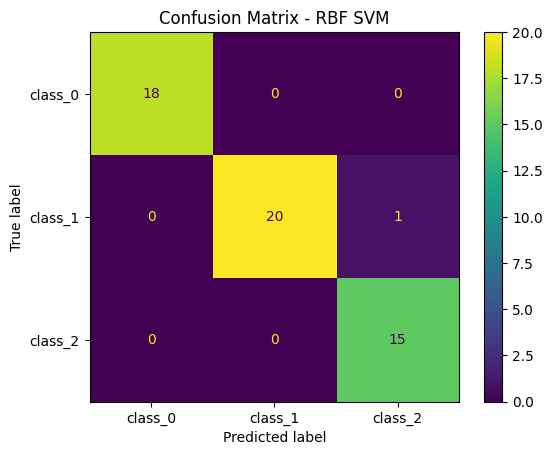

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       1.00      0.95      0.98        21
     class_2       0.94      1.00      0.97        15

    accuracy                           0.98        54
   macro avg       0.98      0.98      0.98        54
weighted avg       0.98      0.98      0.98        54



In [ ]:
y_pred = best_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot()

plt.title(f"Confusion Matrix - {best_name} SVM")
plt.show()

print(classification_report(y_test, y_pred, target_names=class_names))